In [1]:
from pathlib import Path
from PIL import Image, ImageFile
from torch.utils.data import Dataset, DataLoader
import torch
from torchvision import transforms, models
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

Image.MAX_IMAGE_PIXELS = None
ImageFile.LOAD_TRUNCATED_IMAGES = True


In [ ]:
# Assume you put everthing in the current working directory
image_folder = Path("Folder of unzipped images")
label_path = Path("TrainData.xlsx")
model_path = Path("B16_L4_S2_S.pth")

# We will save the model predictions to an Excel file
output_file = Path("The output file.xlsx")

# Make it smaller if you have memory issues
batch_size = 32 

# The confidence threshold for classifying a house as "A"
threshold = 0.5
class_map = {0: "H", 1: "A"}


In [3]:
# Convert the original ID/year table to one row per labeled image.
labels = pd.read_excel(label_path)
ground_truth = labels.melt(id_vars="id", var_name="year", value_name="true_label").dropna(subset=["true_label"])
ground_truth["filename"] = (
    ground_truth["id"].map(lambda name: Path(name).stem)
    + "_" + ground_truth["year"].astype(str) + ".jpg"
)
image_paths = [image_folder / name for name in ground_truth["filename"]]

In [ ]:
# If Windows or Linux, use CUDA if available, otherwise use CPU
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu") 

# If MacOS, use MPS if available, otherwise use CPU. 
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")  

# The architecture of the model can be directly called here
model = models.resnet50(weights=None) 

# Truncate the output layer into 2 classes
model.fc = nn.Linear(model.fc.in_features, 2) 

# Load our own weights
model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True)) 
model.to(device)

# Evaluatetion model so that the model does not update the weights during inference
model.eval() 

# Normalize the format of the input images
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])




In [5]:
class ImageFolderDataset(Dataset):
    def __init__(self, image_paths, transform):
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        path = self.image_paths[idx]
        with Image.open(path) as image:
            image = image.convert("RGB")
        return self.transform(image), path.name

dataset = ImageFolderDataset(image_paths, transform)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False)


# Apply the trained model to the images
results = []
with torch.no_grad():
    for images, filenames in tqdm(dataloader):
        outputs = model(images.to(device))
        probs_A = F.softmax(outputs, dim=1)[:, 1].cpu().numpy()
        predictions = (probs_A >= threshold).astype(int)
        for filename, pred, prob_A in zip(filenames, predictions, probs_A):
            results.append({"filename": filename, "predicted_label": class_map[pred], "prob_A": float(prob_A)})

evaluation = ground_truth.merge(pd.DataFrame(results), on="filename")
evaluation["is_correct"] = evaluation["true_label"] == evaluation["predicted_label"]
predicted_labels = evaluation.pivot(index="id", columns="year", values="predicted_label")
predicted_labels = predicted_labels.reindex(index=labels["id"], columns=labels.columns.drop("id")).reset_index()
predicted_labels.to_excel(output_file, index=False)
evaluation.head()

  0%|          | 0/200 [00:00<?, ?it/s]

,id,year,true_label,filename,predicted_label,prob_A,is_correct
0,house_10518516.jpg,2011,A,house_10518516_2011.jpg,A,0.926503,True
1,house_10531146.jpg,2011,A,house_10531146_2011.jpg,A,0.676460,True
2,house_10539370.jpg,2011,A,house_10539370_2011.jpg,A,0.846829,True
3,house_10546330.jpg,2011,A,house_10546330_2011.jpg,A,0.884659,True
4,house_10564791.jpg,2011,A,house_10564791_2011.jpg,A,0.875728,True


Accuracy: 95.20%
              precision    recall  f1-score   support

           H     0.9576    0.9660    0.9618      4000
           A     0.9425    0.9287    0.9356      2400

    accuracy                         0.9520      6400
   macro avg     0.9501    0.9474    0.9487      6400
weighted avg     0.9519    0.9520    0.9520      6400



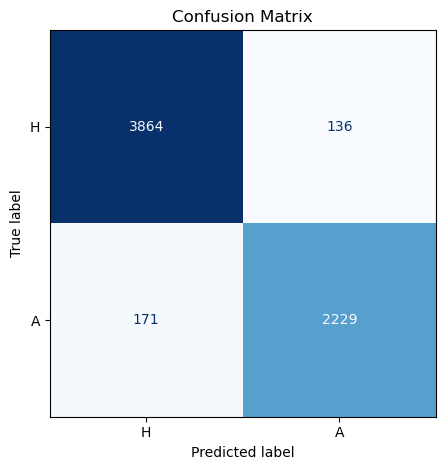

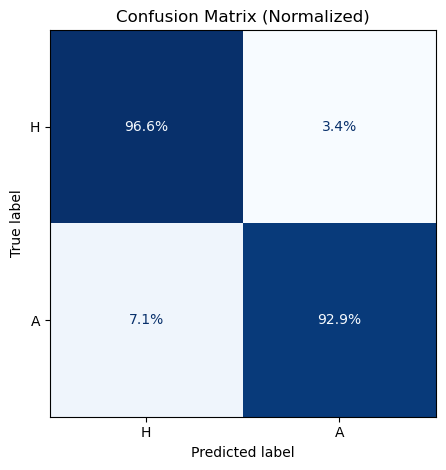

In [6]:
# We show the confusion matrix of the model predictions

y_true = evaluation["true_label"]
y_pred = evaluation["predicted_label"]

print(f"Accuracy: {accuracy_score(y_true, y_pred):.2%}")
print(classification_report(y_true, y_pred, labels=["H", "A"], digits=4, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=["H", "A"], cmap="Blues", colorbar=False
)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=["H", "A"], cmap="Blues", colorbar=False,
    normalize="true", values_format=".1%"
)

plt.title("Confusion Matrix (Normalized)")
plt.tight_layout()
plt.show()
